In [ ]:
import sys
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
GOLD_DB = PROJECT_ROOT / "data" / "gold" / "fraud_dev.duckdb"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)


def q(sql):
    """Run a query on the Gold warehouse (read-only) and return a DataFrame."""
    with duckdb.connect(str(GOLD_DB), read_only=True) as con:
        return con.sql(sql).df()


print("Gold file exists:", GOLD_DB.exists())
q("""
    select count(*)      as n_rows,
           sum(is_fraud) as n_fraud
    from fact_transactions
""")

In [ ]:
monthly = q("""
    select strftime(trans_ts, '%Y-%m')                       as month,
           count(*)                                          as n_txn,
           cast(sum(is_fraud) as integer)                    as n_fraud,
           round(100 * avg(is_fraud), 3)                     as fraud_pct,
           count(distinct case when is_fraud = 1
                               then card_key end)            as fraud_cards
    from fact_transactions
    group by 1
    order by 1
""")

print("total rows :", monthly["n_txn"].sum())
print("total fraud:", monthly["n_fraud"].sum())
monthly

In [ ]:
from src.models.split import TRAIN, GAP, VALIDATION, TEST, assign_split

tx = q("select trans_ts, is_fraud, card_key from fact_transactions")
tx["split"] = assign_split(tx["trans_ts"])

fraud_rows = tx[tx["is_fraud"] == 1]
split_summary = pd.DataFrame({
    "n_txn": tx.groupby("split").size(),
    "n_fraud": tx.groupby("split")["is_fraud"].sum(),
    "fraud_cards": fraud_rows.groupby("split")["card_key"].nunique(),
}).reindex([TRAIN, GAP, VALIDATION, TEST])
split_summary["fraud_pct"] = (100 * split_summary["n_fraud"] / split_summary["n_txn"]).round(3)

print("total rows :", split_summary["n_txn"].sum())
print("total fraud:", split_summary["n_fraud"].sum())
split_summary

In [ ]:
# Which splits does each fraud card appear in?
card_splits = (
    fraud_rows.groupby("card_key")["split"]
    .agg(lambda s: " + ".join(sorted(set(s))))
)
print("fraud cards in total:", card_splits.size)
card_splits.value_counts()

In [ ]:
for table in ["fact_transactions", "dim_card", "dim_merchant", "dim_location", "dim_date"]:
    cols = q(f"describe {table}")[["column_name", "column_type"]]
    print(f"\n{table}:")
    print(", ".join(f"{c} ({t})" for c, t in cols.itertuples(index=False)))

In [ ]:
import time
from src.models.features import build_features, load_model_frame

t0 = time.perf_counter()
frame = load_model_frame(GOLD_DB)
features = build_features(frame)
print(f"built in {time.perf_counter() - t0:.1f} s")

print("rows :", len(frame), "| fraud:", int(frame["is_fraud"].sum()))
print("missing secs_since_prev    :", features["secs_since_prev"].isna().sum())
print("missing amt_vs_card_median :", features["amt_vs_card_median"].isna().sum())
print("missing median_income      :", features["median_household_income"].isna().sum())

high = features["amt_vs_card_median"] > 10
print("ratio > 10 :", int(high.sum()), "rows |", int(frame.loc[high, "is_fraud"].sum()), "fraud")

features.describe().T.round(2)

In [ ]:
key = ["card_key", "trans_ts"]
dup_mask = frame.duplicated(key, keep=False)
dups = frame.loc[dup_mask, key + ["trans_num", "amt", "category", "is_fraud"]].copy()
dups["card_key"] = dups["card_key"].str[:8]
dups = dups.sort_values(key)

groups = dups.groupby(key)
print("rows involved :", len(dups))
print("groups        :", groups.ngroups)
print("rows per group:", groups.size().value_counts().to_dict())
print("fraud rows    :", int(dups["is_fraud"].sum()))
print("same amount in group:", int((groups["amt"].nunique() == 1).sum()), "groups")
dups.head(20)

In [ ]:
from src.models.evaluate import alert_metrics, card_bootstrap, rule_baseline

data = frame[["card_key", "trans_ts", "is_fraud", "gender"]].copy()
data["split"] = assign_split(data["trans_ts"])
rule = rule_baseline(features)

for name in [TRAIN, VALIDATION]:
    m = data["split"] == name
    res = alert_metrics(data.loc[m, "is_fraud"], rule[m], features.loc[m, "amt"])
    days = data.loc[m, "trans_ts"].dt.normalize().nunique()
    print(f"\n{name}: {days} days, {res['alerts'] / days:.1f} alerts/day")
    for k, v in res.items():
        print(f"  {k:15s} {v:,.4f}" if isinstance(v, float) else f"  {k:15s} {v:,}")

# 95% interval for the rule's recall on validation, resampling whole cards
val = (data["split"] == VALIDATION).to_numpy()
y_val = data.loc[val, "is_fraud"].to_numpy()
r_val = rule[val].to_numpy()
amt_val = features.loc[val, "amt"].to_numpy()
ci = card_bootstrap(
    data.loc[val, "card_key"],
    lambda idx: alert_metrics(y_val[idx], r_val[idx], amt_val[idx])["recall"],
)
print(f"\nvalidation recall {ci['estimate']:.3f}  95% CI [{ci['low']:.3f}, {ci['high']:.3f}]")

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.models.evaluate import pr_auc, top_n_mask
from src.models.features import CARD_HISTORY_FEATURES, CATEGORICAL_FEATURES, FEATURE_COLUMNS

LOG_FEATURES = ["amt", "secs_since_prev", "amt_vs_card_median", "city_pop"]
numeric = [c for c in FEATURE_COLUMNS if c not in CATEGORICAL_FEATURES + CARD_HISTORY_FEATURES]
plain = [c for c in numeric if c not in LOG_FEATURES]

prep = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                          FunctionTransformer(np.log1p), StandardScaler()), LOG_FEATURES),
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                          StandardScaler()), plain),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])
logit = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

trn = (data["split"] == TRAIN).to_numpy()
t0 = time.perf_counter()
logit.fit(features[trn], data.loc[trn, "is_fraud"])
print(f"fitted in {time.perf_counter() - t0:.1f} s")

p_val = logit.predict_proba(features[val])[:, 1]
n_alerts = int(r_val.sum())
print(f"\nvalidation PR-AUC   logit {pr_auc(y_val, p_val):.4f} | rule {pr_auc(y_val, r_val):.4f}")

res = alert_metrics(y_val, top_n_mask(p_val, n_alerts), amt_val)
print(f"\nlogit at the rule's workload ({n_alerts:,} alerts):")
for k, v in res.items():
    print(f"  {k:15s} {v:,.4f}" if isinstance(v, float) else f"  {k:15s} {v:,}")

cards_val = data.loc[val, "card_key"]
ci = card_bootstrap(
    cards_val,
    lambda idx: alert_metrics(
        y_val[idx], top_n_mask(p_val[idx], int(r_val[idx].sum())), amt_val[idx]
    )["recall"],
)
print(f"\nlogit recall {ci['estimate']:.3f}  95% CI [{ci['low']:.3f}, {ci['high']:.3f}]")

In [ ]:
def paired_diff(idx, key):
    """Logit minus rule on the SAME resampled cards, at equal workload."""
    n = int(r_val[idx].sum())
    logit_m = alert_metrics(y_val[idx], top_n_mask(p_val[idx], n), amt_val[idx])
    rule_m = alert_metrics(y_val[idx], r_val[idx], amt_val[idx])
    return logit_m[key] - rule_m[key]

for key in ["recall", "precision", "dollar_recall"]:
    d = card_bootstrap(cards_val, lambda idx: paired_diff(idx, key))
    verdict = "real difference" if d["low"] > 0 or d["high"] < 0 else "not distinguishable"
    print(f"{key:14s} diff {d['estimate']:+.3f}  95% CI [{d['low']:+.3f}, {d['high']:+.3f}]  -> {verdict}")

In [ ]:
from src.models.train import fit_final_lgbm, model_columns, tune_lgbm

X_train_all = features.loc[trn]
y_train = data.loc[trn, "is_fraud"].to_numpy()
ts_train = data.loc[trn, "trans_ts"]

VARIANTS = {
    "A_plain":            {"weighted": False, "history": False},
    "B_plain_history":    {"weighted": False, "history": True},
    "C_weighted":         {"weighted": True,  "history": False},
    "D_weighted_history": {"weighted": True,  "history": True},
}

tuning = {}
for name, v in VARIANTS.items():
    cols = model_columns(v["history"])
    t0 = time.perf_counter()
    tuning[name] = tune_lgbm(X_train_all[cols], y_train, ts_train, weighted=v["weighted"])
    print(f"\n{name}  ({time.perf_counter() - t0:.0f} s)")
    print(tuning[name].round(4).to_string(index=False))

In [ ]:
preds = {"rule": r_val.astype(float), "logit": p_val}
final_models = {}

for name, v in VARIANTS.items():
    cols = model_columns(v["history"])
    row = tuning[name].iloc[0]
    best = {k: int(row[k]) for k in ["num_leaves", "min_child_samples", "best_iteration"]}
    t0 = time.perf_counter()
    model = fit_final_lgbm(X_train_all[cols], y_train, v["weighted"], best)
    final_models[name] = (model, cols)
    preds[name] = model.predict_proba(features.loc[val, cols])[:, 1]
    print(f"{name}: refit on full train in {time.perf_counter() - t0:.0f} s")

summary = {}
for name, p in preds.items():
    m = alert_metrics(y_val, top_n_mask(p, n_alerts), amt_val)
    summary[name] = {
        "pr_auc": pr_auc(y_val, p),
        "recall": m["recall"],
        "precision": m["precision"],
        "dollar_recall": m["dollar_recall"],
        "fraud_caught": m["fraud_caught"],
    }
print(f"\nvalidation, {n_alerts:,} alerts for every model:")
pd.DataFrame(summary).T.round(4)

In [ ]:
days_val = 85
budgets = [250, 500, 1000, 2000, n_alerts]
rows = []
for b in budgets:
    for name, p in preds.items():
        if name == "rule":
            continue  # the rule has a fixed number of alerts
        m = alert_metrics(y_val, top_n_mask(p, b), amt_val)
        rows.append({"alerts": b, "per_day": round(b / days_val, 1), "model": name,
                     "recall": m["recall"], "dollar_recall": m["dollar_recall"]})
curve = pd.DataFrame(rows)

print("RECALL (share of fraud cases caught)")
print(curve.pivot(index=["alerts", "per_day"], columns="model", values="recall").round(3))
print("\nDOLLAR RECALL (share of fraud dollars caught)")
print(curve.pivot(index=["alerts", "per_day"], columns="model", values="dollar_recall").round(3))

In [ ]:
    BUDGET = 1000

def paired(idx, a, b, metric):
    """Model a minus model b on the SAME resampled cards."""
    y, amt = y_val[idx], amt_val[idx]
    pa, pb = preds[a][idx], preds[b][idx]
    if metric == "pr_auc":
        return pr_auc(y, pa) - pr_auc(y, pb)
    ma = alert_metrics(y, top_n_mask(pa, BUDGET), amt)
    mb = alert_metrics(y, top_n_mask(pb, BUDGET), amt)
    return ma[metric] - mb[metric]

t0 = time.perf_counter()
rows = []
for other in ["B_plain_history", "C_weighted", "D_weighted_history"]:
    for metric in ["pr_auc", "recall", "dollar_recall"]:
        d = card_bootstrap(cards_val, lambda idx: paired(idx, "A_plain", other, metric), n_boot=300)
        rows.append({
            "comparison": f"A - {other}", "metric": metric,
            "diff": d["estimate"], "low": d["low"], "high": d["high"],
            "verdict": "real" if d["low"] > 0 or d["high"] < 0 else "not distinguishable",
        })
print(f"done in {time.perf_counter() - t0:.0f} s")
pd.DataFrame(rows).round(4)

In [ ]:
import subprocess

import mlflow

from src.models import split as split_mod
from src.models.evaluate import RULE_AMOUNT
from src.models.train import SEED

# Where runs are stored: one local SQLite file + one artifact folder (both git-ignored)
MLFLOW_DB = PROJECT_ROOT / "mlflow.db"
ARTIFACTS = PROJECT_ROOT / "mlartifacts"
EXPERIMENT = "fraud-phase4"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location=ARTIFACTS.as_uri())
mlflow.set_experiment(EXPERIMENT)

# Which code produced these numbers
def git(*args):
    return subprocess.run(["git", *args], cwd=PROJECT_ROOT,
                          capture_output=True, text=True).stdout.strip()

commit = git("rev-parse", "--short", "HEAD")
dirty = bool(git("status", "--porcelain"))
base_tags = {"git_commit": commit, "git_dirty": str(dirty), "phase": "4"}

common_params = {
    "train_period": f"{split_mod.TRAIN_START.date()}..{split_mod.TRAIN_END.date()}",
    "validation_period": f"{split_mod.VALID_START.date()}..{split_mod.VALID_END.date()}",
    "gap_days": split_mod.GAP_DAYS,
    "seed": SEED,
    "train_rows": int(trn.sum()), "train_fraud": int(y_train.sum()),
    "val_rows": int(val.sum()), "val_fraud": int(y_val.sum()),
}

def val_metrics(p):
    """Validation metrics at three alert budgets (5,832 = the rule's workload)."""
    out = {"pr_auc": pr_auc(y_val, p)}
    for b in [500, 1000, n_alerts]:
        m = alert_metrics(y_val, top_n_mask(p, b), amt_val)
        out[f"recall_at_{b}"] = m["recall"]
        out[f"precision_at_{b}"] = m["precision"]
        out[f"dollar_recall_at_{b}"] = m["dollar_recall"]
    return out

print("commit:", commit, "| uncommitted changes:", dirty)
print("tracking:", mlflow.get_tracking_uri())

In [22]:
already = mlflow.search_runs(experiment_names=[EXPERIMENT],
                             filter_string=f"tags.git_commit = '{commit}'")
if len(already):
    print(f"{len(already)} runs already logged for commit {commit}; nothing new logged")
else:
    with mlflow.start_run(run_name="rule_night_amount"):
        mlflow.set_tags({**base_tags, "model_type": "rule", "selected": "no"})
        mlflow.log_params({**common_params, "rule": f"is_night and amt > {RULE_AMOUNT}"})
        m = alert_metrics(y_val, r_val, amt_val)
        mlflow.log_metrics({"pr_auc": pr_auc(y_val, r_val),
                            f"recall_at_{n_alerts}": m["recall"],
                            f"precision_at_{n_alerts}": m["precision"],
                            f"dollar_recall_at_{n_alerts}": m["dollar_recall"]})

    with mlflow.start_run(run_name="logistic_regression"):
        logit_cols = model_columns(False)
        mlflow.set_tags({**base_tags, "model_type": "logistic_regression", "selected": "no"})
        mlflow.log_params({**common_params, "n_features": len(logit_cols), "max_iter": 2000})
        mlflow.log_metrics(val_metrics(p_val))
        mlflow.log_text("\n".join(logit_cols), "features.txt")
        # skops (safe format) refuses unknown types; allow exactly the one it reported
        mlflow.sklearn.log_model(logit, name="model", skops_trusted_types=["numpy.dtype"])

    for name, v in VARIANTS.items():
        model, cols = final_models[name]
        best = tuning[name].iloc[0]
        with mlflow.start_run(run_name=name):
            mlflow.set_tags({**base_tags, "model_type": "lightgbm",
                             "selected": "yes" if name == "A_plain" else "no"})
            mlflow.log_params({
                **common_params, "weighted": v["weighted"], "card_history": v["history"],
                "n_features": len(cols),
                "num_leaves": int(best["num_leaves"]),
                "min_child_samples": int(best["min_child_samples"]),
                "n_trees": int(best["best_iteration"]),
                "inner_ap": round(float(best["inner_ap"]), 4),
            })
            mlflow.log_metrics(val_metrics(preds[name]))
            mlflow.log_text("\n".join(cols), "features.txt")
            mlflow.log_text(tuning[name].to_csv(index=False), "inner_tuning.csv")
            mlflow.lightgbm.log_model(model, name="model")
    print(f"logged 6 runs for commit {commit} (uncommitted changes: {dirty})")

runs = mlflow.search_runs(experiment_names=[EXPERIMENT])
runs[["tags.mlflow.runName", "tags.selected", "status", "metrics.pr_auc",
      "metrics.recall_at_1000", "metrics.dollar_recall_at_1000"]].round(4)

logged 6 runs for commit 38b50ff (uncommitted changes: True)


,tags.mlflow.runName,tags.selected,status,metrics.pr_auc,metrics.recall_at_1000,metrics.dollar_recall_at_1000
0,D_weighted_history,no,FINISHED,0.9132,0.8458,0.9401
1,C_weighted,no,FINISHED,0.9162,0.8478,0.9453
2,B_plain_history,no,FINISHED,0.9193,0.8529,0.9395
3,A_plain,yes,FINISHED,0.9203,0.8550,0.9463
4,logistic_regression,no,FINISHED,0.4285,0.4607,0.6916
5,rule_night_amount,no,FINISHED,0.0708,NaN,NaN


SHAP for 228,187 validation rows in 61 s
max reconstruction error: 4.796163466380676e-14

mean |SHAP| per feature (log-odds):
amt                             0.9069
category                        0.6980
amt_vs_card_median              0.3093
is_night                        0.2963
age                             0.2076
card_txn_24h                    0.2028
city_pop                        0.2020
hour                            0.1984
secs_since_prev                 0.1734
median_household_income         0.1354
day_of_week                     0.1198
channel                         0.0825
distance_km                     0.0636
card_txn_1h                     0.0274
is_nationwide_public_holiday    0.0130
has_income                      0.0024
is_bank_holiday                 0.0022
is_public_holiday_in_state      0.0011


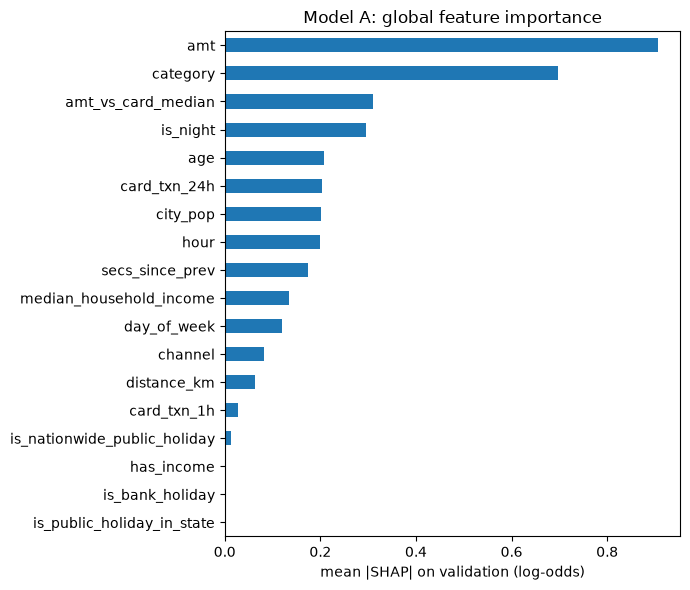

In [23]:
import matplotlib.pyplot as plt

model_a, cols_a = final_models["A_plain"]
X_val_a = features.loc[val, cols_a]

t0 = time.perf_counter()
contrib = model_a.predict(X_val_a, pred_contrib=True)  # SHAP values in log-odds; last column = base value
print(f"SHAP for {len(X_val_a):,} validation rows in {time.perf_counter() - t0:.0f} s")

shap_val = pd.DataFrame(contrib[:, :-1], columns=cols_a, index=X_val_a.index)
base_value = contrib[0, -1]

# Check: base value + sum of SHAP values must reproduce the model's raw score
raw = model_a.predict(X_val_a.iloc[:1000], raw_score=True)
recon = base_value + shap_val.iloc[:1000].sum(axis=1).to_numpy()
print("max reconstruction error:", float(np.abs(raw - recon).max()))

importance = shap_val.abs().mean().sort_values(ascending=False)
print("\nmean |SHAP| per feature (log-odds):")
print(importance.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 6))
importance[::-1].plot.barh(ax=ax)
ax.set_xlabel("mean |SHAP| on validation (log-odds)")
ax.set_title("Model A: global feature importance")
plt.tight_layout()
plt.show()


In [24]:
CUSTOMER = ["age", "city_pop", "median_household_income", "has_income"]
cols_e = [c for c in model_columns(False) if c not in CUSTOMER]

t0 = time.perf_counter()
tuning["E_no_customer"] = tune_lgbm(X_train_all[cols_e], y_train, ts_train, weighted=False)
row = tuning["E_no_customer"].iloc[0]
best_e = {k: int(row[k]) for k in ["num_leaves", "min_child_samples", "best_iteration"]}
model_e = fit_final_lgbm(X_train_all[cols_e], y_train, False, best_e)
final_models["E_no_customer"] = (model_e, cols_e)
preds["E_no_customer"] = model_e.predict_proba(features.loc[val, cols_e])[:, 1]
print(f"E tuned + refit in {time.perf_counter() - t0:.0f} s, {len(cols_e)} features")
print(tuning["E_no_customer"].round(4).to_string(index=False))

rows = []
for metric in ["pr_auc", "recall", "dollar_recall"]:
    d = card_bootstrap(cards_val, lambda idx: paired(idx, "A_plain", "E_no_customer", metric), n_boot=300)
    rows.append({"metric": metric, "A_minus_E": d["estimate"], "low": d["low"], "high": d["high"],
                 "verdict": "real" if d["low"] > 0 or d["high"] < 0 else "not distinguishable"})
pd.DataFrame(rows).round(4)

E tuned + refit in 39 s, 14 features
 num_leaves  min_child_samples  best_iteration  inner_ap
         63                500             334    0.9099
         15                500             951    0.9090
         63                 50             436    0.9055
         15                 50             249    0.8833


,metric,A_minus_E,low,high,verdict
0,pr_auc,0.0466,0.0343,0.0607,real
1,recall,0.0480,0.0293,0.0647,real
2,dollar_recall,0.0534,0.0265,0.0763,real


In [25]:
# 1) Could exact customer features identify a single card?
card_profile = frame.groupby("card_key")[["birth_year", "city_pop", "median_household_income"]].first()
combo_sizes = card_profile.fillna(-1).value_counts()
print(f"cards: {len(card_profile)} | distinct exact combinations: {len(combo_sizes)} | "
      f"unique to one card: {int((combo_sizes == 1).sum())}")

# 2) Variant F: coarse profile only (10-year age band + urban flag, no income)
coarse = features.copy()
coarse["age_band"] = (coarse["age"] // 10) * 10
coarse["urban"] = (coarse["city_pop"] >= 50_000).astype("int8")
cols_f = cols_e + ["age_band", "urban"]
n_groups = coarse.loc[trn].groupby(["age_band", "urban"]).ngroups
print(f"coarse profile groups: {n_groups}")

t0 = time.perf_counter()
X_train_f = coarse.loc[trn, cols_f]
tuning["F_coarse_profile"] = tune_lgbm(X_train_f, y_train, ts_train, weighted=False)
row = tuning["F_coarse_profile"].iloc[0]
best_f = {k: int(row[k]) for k in ["num_leaves", "min_child_samples", "best_iteration"]}
model_f = fit_final_lgbm(X_train_f, y_train, False, best_f)
final_models["F_coarse_profile"] = (model_f, cols_f)
preds["F_coarse_profile"] = model_f.predict_proba(coarse.loc[val, cols_f])[:, 1]
print(f"F tuned + refit in {time.perf_counter() - t0:.0f} s, inner AP {row['inner_ap']:.4f}")

# 3) Where does F sit between A (exact) and E (none)?
rows = []
for a, b in [("A_plain", "F_coarse_profile"), ("F_coarse_profile", "E_no_customer")]:
    for metric in ["pr_auc", "recall"]:
        d = card_bootstrap(cards_val, lambda idx: paired(idx, a, b, metric), n_boot=300)
        rows.append({"comparison": f"{a} - {b}", "metric": metric, "diff": d["estimate"],
                     "low": d["low"], "high": d["high"],
                     "verdict": "real" if d["low"] > 0 or d["high"] < 0 else "not distinguishable"})
pd.DataFrame(rows).round(4)

cards: 999 | distinct exact combinations: 999 | unique to one card: 999
coarse profile groups: 18
F tuned + refit in 70 s, inner AP 0.9461


,comparison,metric,diff,low,high,verdict
0,A_plain - F_coarse_profile,pr_auc,0.0003,-0.0057,0.0068,not distinguishable
1,A_plain - F_coarse_profile,recall,0.0072,-0.0128,0.0191,not distinguishable
2,F_coarse_profile - E_no_customer,pr_auc,0.0462,0.0347,0.0601,real
3,F_coarse_profile - E_no_customer,recall,0.0409,0.0240,0.0621,real
